Step 1: Generate Simulated Data

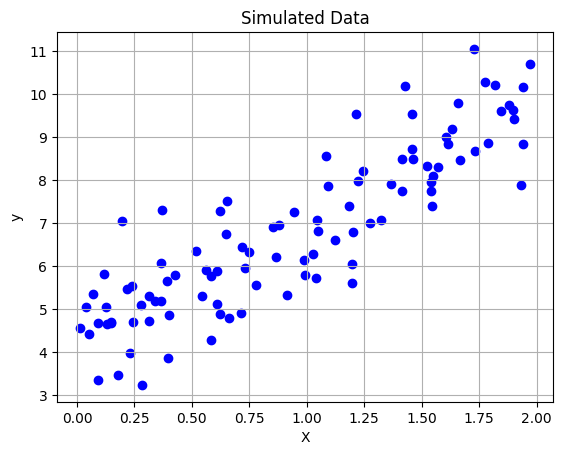

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility (you’ll get the same random numbers every time you run it)
np.random.seed(42)

# Generate 100 random X values between 0 and 2
# np.random.rand(100, 1) generates a 100x1 array of values in [0, 1)
# Multiplying by 2 scales it to [0, 2)
X = 2 * np.random.rand(100, 1)

# Generate corresponding y values using a linear function: y = 4 + 3X + noise
# np.random.randn(100, 1) adds normally-distributed noise (mean=0, std=1)
# This simulates real-world imperfections or random influences (ε)
y = 4 + 3 * X + np.random.randn(100, 1)

# Create a scatter plot of the generated data
plt.scatter(X, y, color="blue")  # Blue dots representing (X, y) pairs

# Label the axes
plt.xlabel("X")  # X-axis label
plt.ylabel("y")  # Y-axis label

# Add a title to the plot
plt.title("Simulated Data")

# Add a grid for better readability
plt.grid(True)

# Display the plot
plt.show()


Step 2: Prepare Data for Linear Regression

Why This Is Important:
X_b = [1, X]
In matrix algebra, the simple linear regression model is:

𝑦
^
=
𝑋
𝑏
⋅
𝜃
y
^
​
 =X
b
​
 ⋅θ
where:

X_b includes a column of 1s for the intercept (α)

θ is a 2x1 column vector:
[
𝛼
,
𝛽
]
𝑇
[α,β]
T


This allows us to write the equation
𝑦
=
𝛼
+
𝛽
𝑥
y=α+βx in matrix form, which is crucial for:

Deriving the normal equation

Performing gradient descent

Training any linear model (in machine learning or econometrics)

💡 Economic View:
The first column (all 1s) ensures that the model includes autonomous consumption (α).

The second column is the actual economic variable, e.g., income (X).

In [ ]:
# Add x0 = 1 to each instance to account for the intercept term in the model
# np.ones((100, 1)) creates a 100x1 column of ones (x0 = 1 for all data points)
# np.c_ concatenates it with X to form X_b (X with bias term)
X_b = np.c_[np.ones((100, 1)), X]  # Shape becomes (100, 2): [1, X]

# Initialize model parameters (theta) with zeros
# theta[0] is the intercept (alpha), theta[1] is the slope (beta)
theta = np.zeros((2, 1))  # Shape (2, 1): [[0], [0]]



In [ ]:
X_b = np.c_[np.ones((100, 1)), X]
theta = np.zeros((2, 1))
print("Initial Theta:\n", theta)


Initial Theta:
 [[0.]
 [0.]]


Step 3: Define Cost Function (MSE)

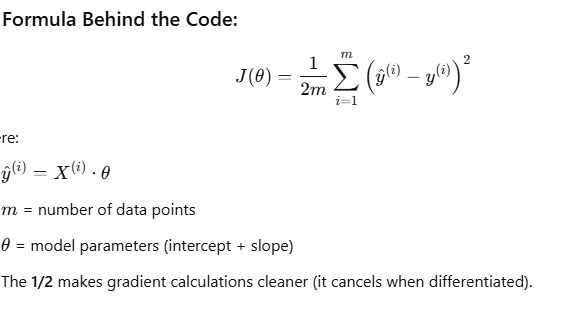

Economic Interpretation:


This cost measures how well your current model explains the variation in consumption based on income.

High cost = poor fit → model needs better parameters.

You’ll later use gradient descent or the normal equation to minimize this cost and get the best α (intercept) and β (MPC).

In [ ]:
# Define a function to compute the cost (error) of linear regression
def compute_cost(X, y, theta):
    m = len(y)  # Number of training examples (rows)

    # Predicted values using current parameters (theta)
    predictions = X.dot(theta)  # Same as Y_hat = X * θ

    # Difference between predicted and actual values
    errors = predictions - y  # This is the residual: ε = ŷ - y

    # Compute the cost function: Mean Squared Error (MSE) divided by 2
    cost = (1 / (2 * m)) * np.sum(errors ** 2)

    return cost  # Return the cost (scalar value)



Step 4: Gradient Descent Implementation

What the Function Does:

Performs batch gradient descent to iteratively update theta so that the cost (error) becomes as small as possible.

Background Formula (Gradient Descent for Linear Regression):
The update rule for parameters is:

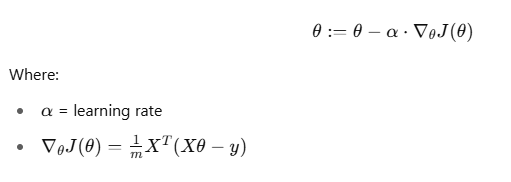

In [ ]:
def gradient_descent(X, y, theta, learning_rate=0.1, n_iterations=100):
    m = len(y)  # Number of training samples
    cost_history = []  # Store cost at each iteration for visualization or analysis

    for i in range(n_iterations):
        # Compute gradients (partial derivatives of cost function w.r.t. each theta)
        gradients = (1 / m) * X.T.dot(X.dot(theta) - y)

        # Update parameters using the gradient and learning rate
        theta = theta - learning_rate * gradients

        # Compute cost with the updated theta
        cost = compute_cost(X, y, theta)
        cost_history.append(cost)

        # Optional: Print progress every 10 steps and at the last iteration
        if i % 10 == 0 or i == n_iterations - 1:
            print(f"Iteration {i}: Cost={cost:.4f}, Theta={theta.ravel()}")

    # Return final optimized parameters and the history of cost values
    return theta, cost_history



Step 5: Run Gradient Descent

Explanation (Step-by-Step):
1. initial_theta = np.zeros((2, 1))
This sets the starting values of θ₀ (intercept) and θ₁ (slope) to 0.

Shape (2,1) matches the two parameters:

𝜃
=
[
0
0
]
θ=[
0
0
​
 ]
2. gradient_descent(...)
You run the gradient_descent() function for 100 iterations with a learning rate of 0.1.

It returns:

final_theta: the best-fit parameter vector
[
𝛼
,
𝛽
]
𝑇
[α,β]
T


cost_history: a list of cost values after each iteration (useful for plotting convergence)

3. final_theta.ravel()
Converts the 2×1 column vector into a 1D array for clean printing.

For example:

python
Copy
Edit
array([[4.12], [2.98]]).ravel()  →  array([4.12, 2.98])

In [ ]:
# Initialize theta to zero
initial_theta = np.zeros((2, 1))

# Run gradient descent
final_theta, cost_history = gradient_descent(X_b, y, initial_theta, learning_rate=0.1, n_iterations=100)

# Display the final optimized parameters
print("\nFinal parameters:", final_theta.ravel())



Iteration 0: Cost=15.9432, Theta=[0.68200041 0.73840826]
Iteration 10: Cost=0.6565, Theta=[3.13862111 3.2108224 ]
Iteration 20: Cost=0.4775, Theta=[3.4960727  3.35452681]
Iteration 30: Cost=0.4550, Theta=[3.62780395 3.28366849]
Iteration 40: Cost=0.4400, Theta=[3.72203906 3.204962  ]
Iteration 50: Cost=0.4293, Theta=[3.79978931 3.13675787]
Iteration 60: Cost=0.4218, Theta=[3.86514361 3.07909763]
Iteration 70: Cost=0.4164, Theta=[3.92020009 3.03049011]
Iteration 80: Cost=0.4126, Theta=[3.96659345 2.98952772]
Iteration 90: Cost=0.4099, Theta=[4.00568803 2.95500938]
Iteration 99: Cost=0.4082, Theta=[4.03558571 2.92861136]

Final parameters: [4.03558571 2.92861136]


Step 6: Plot Cost Function Convergence

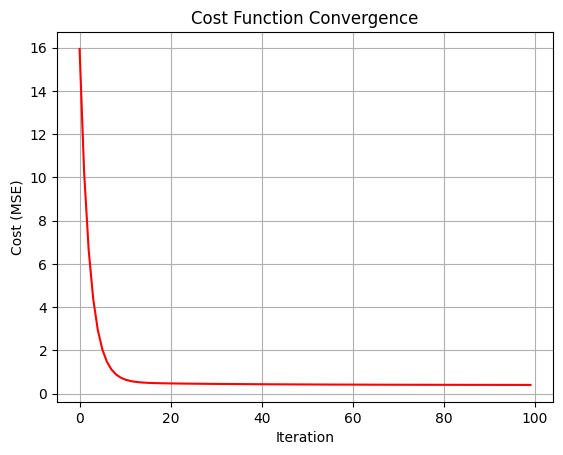

In [ ]:
plt.plot(range(len(cost_history)), cost_history, color="red")  # Plot cost vs. iterations
plt.xlabel("Iteration")             # X-axis label
plt.ylabel("Cost (MSE)")            # Y-axis label (Mean Squared Error)
plt.title("Cost Function Convergence")  # Plot title
plt.grid(True)                      # Adds a grid for readability
plt.show()                          # Display the plot



Step 7: Plot Final Regression Line

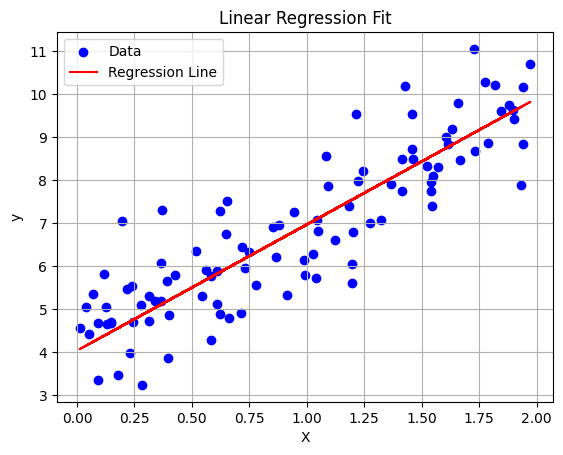

In [ ]:
plt.scatter(X, y, color="blue", label="Data")
plt.plot(X, X_b.dot(final_theta), color="red", label="Regression Line")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression Fit")
plt.legend()
plt.grid(True)
plt.show()
